In [1]:
import warnings
warnings.filterwarnings('ignore')

In [3]:
!pip install torch numpy pandas seaborn matplotlib scipy

     -------------------------------------- 126.7/126.7 MB 5.9 MB/s eta 0:00:00
     -------------------------------------- 294.9/294.9 kB 8.9 MB/s eta 0:00:00
     ---------------------------------------- 9.3/9.3 MB 7.7 MB/s eta 0:00:00
     ---------------------------------------- 36.6/36.6 MB 6.7 MB/s eta 0:00:00
     -------------------------------------- 218.0/218.0 kB 6.5 MB/s eta 0:00:00
     -------------------------------------- 876.3/876.3 kB 9.2 MB/s eta 0:00:00
  Using cached sympy-1.14.0-py3-none-any.whl (6.3 MB)
  Using cached networkx-3.6.1-py3-none-any.whl (2.1 MB)
  Using cached jinja2-3.1.6-py3-none-any.whl (134 kB)
  Using cached fsspec-2026.9.0-py3-none-any.whl (221 kB)
  Using cached contourpy-1.3.3-cp311-cp311-win_amd64.whl (225 kB)
  Using cached cycler-0.12.1-py3-none-any.whl (8.3 kB)
     ---------------------------------------- 1.7/1.7 MB 10.7 MB/s eta 0:00:00
     ---------------------------------------- 70.7/70.7 kB 1.9 MB/s eta 0:00:00
     ----------------


[notice] A new release of pip available: 22.3 -> 26.3
[notice] To update, run: C:\Users\carol\AppData\Local\Programs\Python\Python311\python.exe -m pip install --upgrade pip


In [2]:
import sys, subprocess
print("kernel python:", sys.executable)
print(subprocess.run([sys.executable, "-m", "pip", "list"], capture_output=True, text=True).stdout[:1500])

kernel python: c:\Users\carol\AppData\Local\Programs\Python\Python310\python.exe
Package           Version
----------------- ---------
asttokens         3.0.2
certifi           2025.1.31
colorama          0.4.6
comm              0.2.3
debugpy           1.8.22
decorator         5.3.1
distlib           0.3.9
exceptiongroup    1.3.1
executing         2.3.0
filelock          3.17.0
ipykernel         7.3.0
ipython           8.39.0
jedi              0.20.1
jupyter_client    8.10.0
jupyter_core      5.9.1
matplotlib-inline 0.2.2
nest-asyncio2     1.7.4
packaging         24.2
parso             0.8.7
pip               23.0.1
pipenv            2024.4.1
platformdirs      4.3.6
prompt_toolkit    3.0.53
psutil            7.2.2
pure_eval         0.2.4
Pygments          2.21.0
python-dateutil   3.0.0
pyzmq             27.3.0
setuptools        75.8.2
six               1.17.0
stack-data        0.6.3
tornado           6.5.10
traitlets         5.16.1
typing_extensions 4.16.0
tzdata            2026.6
virt

In [3]:
import sys
print(sys.executable)
import matplotlib.pyplot as plt
import math
import json
import numpy as np
import torch
import pickle
import torch.nn as nn
import pandas as pd
import seaborn as sns
import torch.optim as optim
import torch.nn.functional as F
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader
from matplotlib.pyplot import scatter, figure
from scipy import stats
from numpy.ma.core import outer
from sys import stderr


c:\Users\carol\AppData\Local\Programs\Python\Python310\python.exe


In [4]:
start = -7
end = 7
n = 300
batch_size = 16
modelSamples = 50

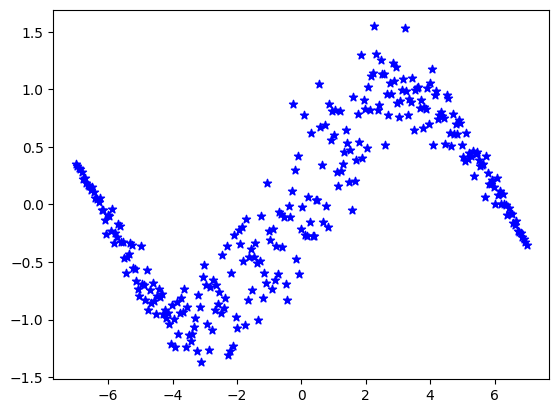

In [5]:
def sample_dataset(start, end, n):
    np.random.seed(0)
    x = np.linspace(start, end, n)
    sample_mean = [math.sin(i/2) for i in x]

    sample_var = [abs((abs(start)+abs(end))/2 - abs(i))/16 for i in x]
    y = stats.norm(sample_mean, sample_var).rvs(random_state=0)
    return x, y

x_train, y_train = sample_dataset(start, end, n)
scatter(x_train, y_train, c="blue", marker="*")

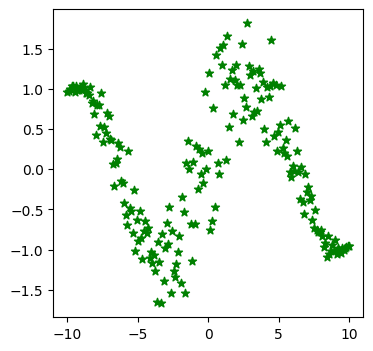

In [6]:
figure(figsize=(4, 4))
# Not exactely the same distribution, but works for now
x_test, y_test = sample_dataset(-10, 10, 200)
scatter(x_test, y_test, c="green", marker="*")

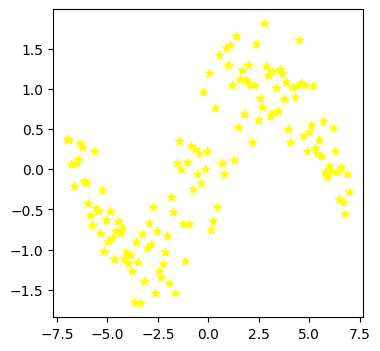

In [7]:
#Plotting In Training Distribution Data Points in the Test Set
# Filter the data to retain only the desired ranges
mask =  (x_test >= -7) &  (x_test <= 7) # Select the ranges -10 to -7 and 7 to 10
x_test_idd = x_test[mask]
y_test_idd = y_test[mask]

plt.figure(figsize=(4, 4))
plt.scatter(x_test_idd, y_test_idd, c="yellow", marker="*")

plt.show()


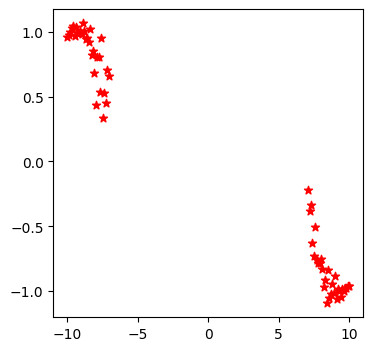

In [8]:
#Plotting Out of Training Distribution Data Points in the Test Set
# Filter the data to retain only the desired ranges
mask = (x_test >= -10) & (x_test < -7) | (x_test > 7) & (x_test <= 10) # Select the ranges -10 to -7 and 7 to 10
x_test_oodd = x_test[mask]
y_test_oodd = y_test[mask]

plt.figure(figsize=(4, 4))
plt.scatter(x_test_oodd, y_test_oodd, c="red", marker="*")

plt.show()


In [9]:

# Train
tensor_x = torch.Tensor(x_train).unsqueeze(1)
tensor_y = torch.Tensor(y_train).unsqueeze(1)
train_dataset = TensorDataset(tensor_x, tensor_y)
train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)

#Test for OODD (Out of Data Distribution)
tensor_x_test_oodd = torch.Tensor(x_test_oodd).unsqueeze(1)
tensor_y_test_oodd = torch.Tensor(y_test_oodd).unsqueeze(1)
test_dataset_oodd = TensorDataset(tensor_x_test_oodd, tensor_y_test_oodd)
test_loader_oodd = DataLoader(test_dataset_oodd, batch_size=batch_size, shuffle=True)

#Test for IDD (In Data Distribution)
tensor_x_test_idd = torch.Tensor(x_test_idd).unsqueeze(1)
tensor_y_test_idd = torch.Tensor(y_test_idd).unsqueeze(1)
test_dataset_idd = TensorDataset(tensor_x_test_idd, tensor_y_test_idd)
test_loader_idd = DataLoader(test_dataset_idd, batch_size=batch_size, shuffle=True)

# Test
tensor_x_test = torch.Tensor(x_test).unsqueeze(1)
tensor_y_test = torch.Tensor(y_test).unsqueeze(1)
test_dataset = TensorDataset(tensor_x_test, tensor_y_test)
test_loader = DataLoader(test_dataset, batch_size=batch_size, shuffle=True)

In [10]:
class DeepONet(nn.Module):
    def __init__(self):
        super(DeepONet, self).__init__()
        self.hidden_size = 35

        # We only have 1 input feature
        self.b1 = nn.Linear(1, self.hidden_size)
        self.b2 = nn.Linear(self.hidden_size, self.hidden_size)

        self.t1 = nn.Linear(self.hidden_size, self.hidden_size)
        self.t2 = nn.Linear(self.hidden_size, self.hidden_size)

        self.mu = nn.Linear(self.hidden_size, 1)
        self.var = nn.Linear(self.hidden_size, 1)

    def forward(self, x):

        h = torch.tanh(self.b1(x))
        h = torch.tanh(self.b2(h))

        input_noise = torch.normal(0, 1, size=(x.shape[0], self.hidden_size))

        t           = torch.tanh(self.t1(input_noise))
        t           = torch.tanh(self.t2(t))
        prod        = torch.multiply(t,h)

        mu = self.mu(prod)
        # Exponential activation to enforce positive var

        var = torch.exp(self.var(prod))
        return mu, var


In [13]:

def plot_with_confidence_interval(model, tensor_x_test, tensor_y_test, x_test,y_test,color,start, end):
    # Get predictions
    mus = []
    vars = []
    for m in range(modelSamples):
        mu, var = model(tensor_x_test)
        mus.append(mu)
        vars.append(var)
    # Total predictive uncertainty: independent variances add, then one square root.
    # Corrected Nov 2026. Original line added std devs and took sqrt of the epistemic std:
    #   stds = stack(mus).std(0)**(1/2) + stack(vars).mean(0)**(1/2)
    mus_stack  = torch.stack(mus)                 # [modelSamples, N, 1]
    vars_stack = torch.stack(vars)
    means = mus_stack.mean(axis=0).detach().numpy()
    epistemic_var = mus_stack.var(axis=0)         # spread of means across stochastic passes
    aleatoric_var = vars_stack.mean(axis=0)       # mean predicted noise variance
    stds = torch.sqrt(epistemic_var + aleatoric_var).detach().numpy()
    mu = means
    sigma = stds
    # Calculate the 95% confidence interval
    lower_bound = mu - 2 * sigma
    upper_bound = mu + 2 * sigma
    # Count the data points within the confidence interval
    count_within_ci = np.sum((tensor_y_test.numpy() >= lower_bound) & (tensor_y_test.numpy() <= upper_bound))
    percentage_count_within_ci = (count_within_ci / tensor_y_test.shape[0]) * 100
    print(f'Number of data points within the 95% confidence interval: {count_within_ci}')
    print(f'Percentage of data points within the 95% confidence interval: {percentage_count_within_ci}')
    # ~ 95% conf. interval (see https://en.wikipedia.org/wiki/1.96)
    y_vals = [mu, mu + 2 * sigma, mu - 2 * sigma]
    dfs = []
    print("y_vals ",y_vals)
    # Create DF from predictions
    for i in range(3):
        data = {
            "x": list(tensor_x_test.squeeze().numpy()),
            "y": list(y_vals[i].squeeze())
        }
        temp = pd.DataFrame.from_dict(data)
        dfs.append(temp)
    df = pd.concat(dfs).reset_index()
    # Plot predictions with confidence
    sns.set(rc={'figure.figsize': (4, 4)})
    sns_plot = sns.lineplot(data=df, x="x", y="y")
    # Highlight training range
    plt.axvline(x=start)
    plt.axvline(x=end)
    # Plot test data on top
    scatter(x_test, y_test, c=color, marker="*", alpha=0.5)
    plt.show()
    return percentage_count_within_ci


In [14]:


def train_and_evaluate_net(net, train_loader, test_loader, tensor_x_test, tensor_y_test,  x_test,y_test,color,num_epochs=150, learning_rate=0.001):
    # Define loss and optimizer
    device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")
    criterion = torch.nn.GaussianNLLLoss(eps=1e-02)
    optimizer = optim.Adam(net.parameters(), lr=learning_rate)
    net.train()
    net.to(device)

    for epoch in range(num_epochs):
        # Train loop
        for batch in train_loader:
            x, y = batch[0].to(device), batch[1].to(device)
            optimizer.zero_grad()
            mu, var = net(x)
            loss = criterion(mu, y, var)
            loss.backward()
            optimizer.step()
            criterionmse_train = nn.MSELoss()
            mse_train = criterionmse_train(mu, y)
        if epoch % 10 == 0:
            all_test_losses = []
            all_mse_test = []
            # Test loop
            for batch in test_loader:
                x, y = batch[0].to(device), batch[1].to(device)
                mu, var = net(x)
                all_test_losses.append(criterion(mu, y, var).item())
                criterionmse_test = nn.MSELoss()
                all_mse_test.append(criterionmse_test(mu, y).item())
            test_loss = sum(all_test_losses) / len(all_test_losses)
            test_mse = sum(all_mse_test) / len(all_mse_test)
    percentage_count_within_ci=plot_with_confidence_interval(net, tensor_x_test, tensor_y_test,x_test,y_test,color,start, end)
    return loss, test_loss, mse_train, test_mse,net,percentage_count_within_ci

def Neural_Network(net,train_loader,test_loader,tensor_x_test,tensor_y_test, x_test,y_test,color):
    loss, test_loss, mse_train, test_mse,net,percentage_count_within_ci = train_and_evaluate_net(net, train_loader, test_loader,tensor_x_test,tensor_y_test, x_test,y_test,color)
    return loss, test_loss, mse_train, test_mse,net,percentage_count_within_ci



In [15]:

# Example JSON string
json_str = '''
{
  "test_loaders": ["test_loader", "test_loader_oodd", "test_loader_idd"],
  "test_tensors_x":["tensor_x_test","tensor_x_test_oodd","tensor_x_test_idd"],
  "test_tensors_y":["tensor_y_test","tensor_y_test_oodd","tensor_y_test_idd"],
  "color":["green","red","yellow"],
  "testset_x":["x_test","x_test_oodd","x_test_idd"],
  "testset_y":["y_test","y_test_oodd","y_test_idd"],
  "output_dirs": ["pickled_models_", "pickled_models_oodd_", "pickled_models_idd_"],
  "error_metrics":["em","em_oodd","em_idd"]
}
'''

# Parse JSON
data = json.loads(json_str)

# Map string names to actual variables
test_loader_vars = {
    "test_loader": test_loader,
    "test_loader_oodd": test_loader_oodd,
    "test_loader_idd": test_loader_idd
}
tensor_x_mapping = {
    "tensor_x_test": tensor_x_test,
    "tensor_x_test_oodd": tensor_x_test_oodd,
    "tensor_x_test_idd": tensor_x_test_idd
}

tensor_y_mapping = {
    "tensor_y_test": tensor_y_test,
    "tensor_y_test_oodd": tensor_y_test_oodd,
    "tensor_y_test_idd": tensor_y_test_idd
}
testset_x_mapping = {
    "x_test": x_test,
    "x_test_oodd": x_test_oodd,
    "x_test_idd": x_test_idd
}

# Mapping from string names to actual variables for testset_y
testset_y_mapping = {
    "y_test": y_test,
    "y_test_oodd": y_test_oodd,
    "y_test_idd": y_test_idd
}

# Access corresponding values using a loop
test_loaders = data["test_loaders"]
test_tensors_x=data["test_tensors_x"]
test_tensors_y=data["test_tensors_y"]
color=data["color"]
testset_x=data["testset_x"]
testset_y=data["testset_y"]
output_dirs = data["output_dirs"]
error_mets=data["error_metrics"]



Number of data points within the 95% confidence interval: 130
Percentage of data points within the 95% confidence interval: 65.0
y_vals  [array([[ 1.2665153 ],
       [ 1.241719  ],
       [ 1.2235962 ],
       [ 1.1982106 ],
       [ 1.1757715 ],
       [ 1.1575266 ],
       [ 1.1340932 ],
       [ 1.1084592 ],
       [ 1.0849077 ],
       [ 1.0571978 ],
       [ 1.0342593 ],
       [ 1.0097083 ],
       [ 0.97641504],
       [ 0.95424116],
       [ 0.9230146 ],
       [ 0.8929155 ],
       [ 0.86087453],
       [ 0.8321716 ],
       [ 0.79935175],
       [ 0.76957923],
       [ 0.7357646 ],
       [ 0.7010095 ],
       [ 0.6683999 ],
       [ 0.6329039 ],
       [ 0.5962015 ],
       [ 0.55835074],
       [ 0.5227524 ],
       [ 0.48255557],
       [ 0.44371957],
       [ 0.40166488],
       [ 0.3594743 ],
       [ 0.32070962],
       [ 0.27696067],
       [ 0.23213054],
       [ 0.18630178],
       [ 0.14069737],
       [ 0.09188117],
       [ 0.04471051],
       [-0.00278871],
    

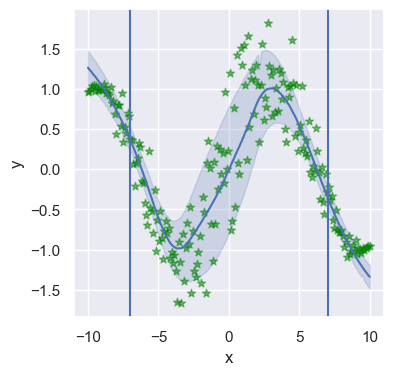

Number of data points within the 95% confidence interval: 125
Percentage of data points within the 95% confidence interval: 62.5
y_vals  [array([[ 1.2659137 ],
       [ 1.2426317 ],
       [ 1.2270677 ],
       [ 1.2043325 ],
       [ 1.1849345 ],
       [ 1.1645746 ],
       [ 1.1420732 ],
       [ 1.1179918 ],
       [ 1.0959413 ],
       [ 1.0735445 ],
       [ 1.052116  ],
       [ 1.017643  ],
       [ 0.99513674],
       [ 0.9689014 ],
       [ 0.9373344 ],
       [ 0.90989476],
       [ 0.8805578 ],
       [ 0.85000384],
       [ 0.8190176 ],
       [ 0.78191096],
       [ 0.7500561 ],
       [ 0.71665484],
       [ 0.6816302 ],
       [ 0.64569384],
       [ 0.60543746],
       [ 0.57048416],
       [ 0.5275642 ],
       [ 0.48578048],
       [ 0.44665188],
       [ 0.40226996],
       [ 0.35963172],
       [ 0.31410447],
       [ 0.27011207],
       [ 0.22713622],
       [ 0.1788601 ],
       [ 0.13084513],
       [ 0.08036154],
       [ 0.03212742],
       [-0.01682966],
    

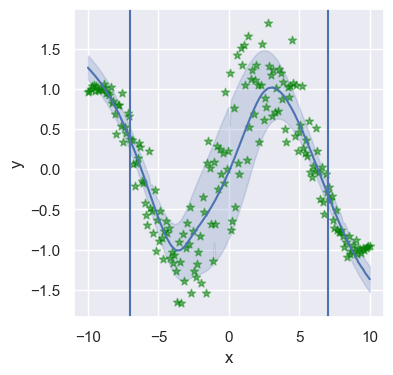

Number of data points within the 95% confidence interval: 123
Percentage of data points within the 95% confidence interval: 61.5
y_vals  [array([[ 1.5640553 ],
       [ 1.5370643 ],
       [ 1.5126052 ],
       [ 1.4805226 ],
       [ 1.4516388 ],
       [ 1.4195348 ],
       [ 1.3894527 ],
       [ 1.3612416 ],
       [ 1.3285308 ],
       [ 1.2947263 ],
       [ 1.2605755 ],
       [ 1.2200285 ],
       [ 1.1889218 ],
       [ 1.1505362 ],
       [ 1.1083724 ],
       [ 1.0729423 ],
       [ 1.0349997 ],
       [ 0.99112976],
       [ 0.9591252 ],
       [ 0.91832143],
       [ 0.8714846 ],
       [ 0.8277716 ],
       [ 0.786687  ],
       [ 0.74120337],
       [ 0.69164103],
       [ 0.6478162 ],
       [ 0.6015459 ],
       [ 0.5557395 ],
       [ 0.5066442 ],
       [ 0.4550702 ],
       [ 0.40475726],
       [ 0.35618836],
       [ 0.30703536],
       [ 0.25152704],
       [ 0.2034774 ],
       [ 0.15070787],
       [ 0.09832849],
       [ 0.04634907],
       [-0.0065743 ],
    

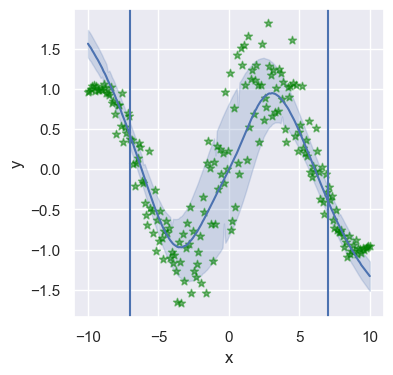

Number of data points within the 95% confidence interval: 124
Percentage of data points within the 95% confidence interval: 62.0
y_vals  [array([[ 1.4018273 ],
       [ 1.3823596 ],
       [ 1.3608727 ],
       [ 1.3379068 ],
       [ 1.3092167 ],
       [ 1.2950493 ],
       [ 1.2649864 ],
       [ 1.2421384 ],
       [ 1.2139513 ],
       [ 1.1868315 ],
       [ 1.1620781 ],
       [ 1.1289811 ],
       [ 1.1008356 ],
       [ 1.066972  ],
       [ 1.0391158 ],
       [ 1.0114048 ],
       [ 0.97491044],
       [ 0.9426114 ],
       [ 0.90374845],
       [ 0.8710466 ],
       [ 0.83169633],
       [ 0.7948851 ],
       [ 0.7558174 ],
       [ 0.71511596],
       [ 0.6775485 ],
       [ 0.634029  ],
       [ 0.5921972 ],
       [ 0.54895633],
       [ 0.5040968 ],
       [ 0.4571293 ],
       [ 0.41386378],
       [ 0.36698768],
       [ 0.318699  ],
       [ 0.27053845],
       [ 0.22108649],
       [ 0.1700173 ],
       [ 0.122776  ],
       [ 0.07049739],
       [ 0.01880532],
    

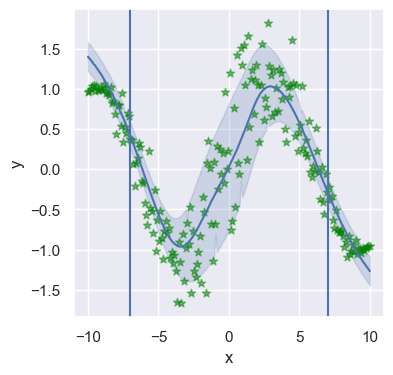

Number of data points within the 95% confidence interval: 120
Percentage of data points within the 95% confidence interval: 60.0
y_vals  [array([[ 1.4230816 ],
       [ 1.3982782 ],
       [ 1.3750926 ],
       [ 1.3492447 ],
       [ 1.326354  ],
       [ 1.2981558 ],
       [ 1.2656643 ],
       [ 1.2433013 ],
       [ 1.218369  ],
       [ 1.1843683 ],
       [ 1.1586447 ],
       [ 1.130492  ],
       [ 1.0949626 ],
       [ 1.0675288 ],
       [ 1.0323079 ],
       [ 1.00159   ],
       [ 0.96662104],
       [ 0.9332754 ],
       [ 0.8991079 ],
       [ 0.8644434 ],
       [ 0.8274288 ],
       [ 0.7884663 ],
       [ 0.75137883],
       [ 0.7085817 ],
       [ 0.6681014 ],
       [ 0.6310437 ],
       [ 0.5901621 ],
       [ 0.5474268 ],
       [ 0.5040171 ],
       [ 0.45617703],
       [ 0.4127335 ],
       [ 0.36564744],
       [ 0.32004258],
       [ 0.27266446],
       [ 0.22020938],
       [ 0.17160872],
       [ 0.12166351],
       [ 0.0714489 ],
       [ 0.01753739],
    

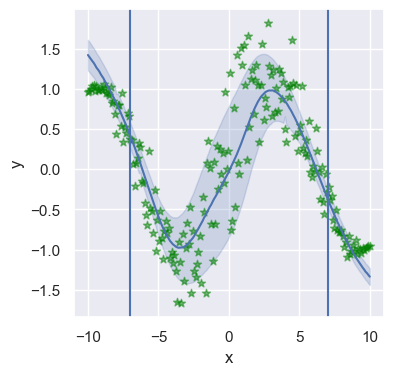

Number of data points within the 95% confidence interval: 126
Percentage of data points within the 95% confidence interval: 63.0
y_vals  [array([[ 1.1096841 ],
       [ 1.0911605 ],
       [ 1.0746124 ],
       [ 1.0567096 ],
       [ 1.0397208 ],
       [ 1.0212603 ],
       [ 1.0044469 ],
       [ 0.98109496],
       [ 0.96380913],
       [ 0.9411728 ],
       [ 0.92143893],
       [ 0.9004977 ],
       [ 0.8744272 ],
       [ 0.85778135],
       [ 0.82874143],
       [ 0.8088763 ],
       [ 0.78256285],
       [ 0.75527704],
       [ 0.7292339 ],
       [ 0.70200914],
       [ 0.6750463 ],
       [ 0.6448914 ],
       [ 0.61515975],
       [ 0.58487344],
       [ 0.55138516],
       [ 0.5190167 ],
       [ 0.48317033],
       [ 0.4481372 ],
       [ 0.41279396],
       [ 0.3735956 ],
       [ 0.33764237],
       [ 0.29691133],
       [ 0.25417897],
       [ 0.2122247 ],
       [ 0.16818893],
       [ 0.12156358],
       [ 0.07762163],
       [ 0.02673827],
       [-0.021587  ],
    

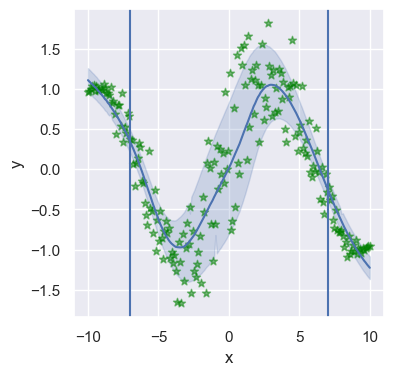

Number of data points within the 95% confidence interval: 124
Percentage of data points within the 95% confidence interval: 62.0
y_vals  [array([[ 1.2203568 ],
       [ 1.1986537 ],
       [ 1.1904397 ],
       [ 1.1703706 ],
       [ 1.1545385 ],
       [ 1.1343355 ],
       [ 1.1169451 ],
       [ 1.0998874 ],
       [ 1.0763383 ],
       [ 1.0623137 ],
       [ 1.0408041 ],
       [ 1.020736  ],
       [ 0.9962608 ],
       [ 0.97368604],
       [ 0.9497149 ],
       [ 0.9245992 ],
       [ 0.90016073],
       [ 0.8744072 ],
       [ 0.84758246],
       [ 0.8197578 ],
       [ 0.78952354],
       [ 0.76160264],
       [ 0.7303432 ],
       [ 0.69873506],
       [ 0.6625645 ],
       [ 0.62938356],
       [ 0.59519845],
       [ 0.558614  ],
       [ 0.5222227 ],
       [ 0.48363262],
       [ 0.44214344],
       [ 0.3995038 ],
       [ 0.36066487],
       [ 0.31580678],
       [ 0.27019635],
       [ 0.22446454],
       [ 0.1809636 ],
       [ 0.13125622],
       [ 0.08235359],
    

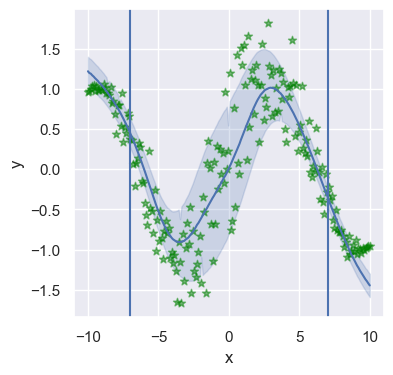

Number of data points within the 95% confidence interval: 126
Percentage of data points within the 95% confidence interval: 63.0
y_vals  [array([[ 1.2962097 ],
       [ 1.276462  ],
       [ 1.2529503 ],
       [ 1.2332939 ],
       [ 1.2145725 ],
       [ 1.1959227 ],
       [ 1.1685351 ],
       [ 1.1451755 ],
       [ 1.1223321 ],
       [ 1.1012665 ],
       [ 1.0714693 ],
       [ 1.0465428 ],
       [ 1.0202205 ],
       [ 0.98946744],
       [ 0.9593813 ],
       [ 0.92969084],
       [ 0.8969985 ],
       [ 0.8680779 ],
       [ 0.8347056 ],
       [ 0.800387  ],
       [ 0.7650105 ],
       [ 0.72876143],
       [ 0.6932563 ],
       [ 0.6555527 ],
       [ 0.614409  ],
       [ 0.57765067],
       [ 0.5354562 ],
       [ 0.49338964],
       [ 0.45241004],
       [ 0.4083916 ],
       [ 0.36403707],
       [ 0.31758842],
       [ 0.27397335],
       [ 0.22549641],
       [ 0.17626818],
       [ 0.12881158],
       [ 0.08006202],
       [ 0.02878467],
       [-0.02017134],
    

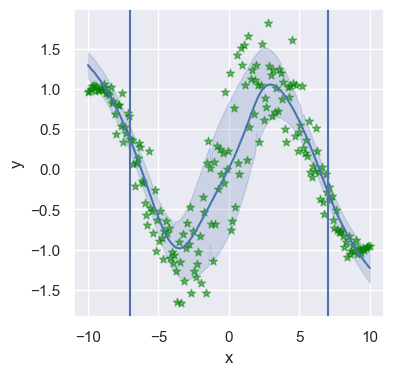

Number of data points within the 95% confidence interval: 133
Percentage of data points within the 95% confidence interval: 66.5
y_vals  [array([[ 1.1284418 ],
       [ 1.1096748 ],
       [ 1.0978636 ],
       [ 1.076375  ],
       [ 1.0602136 ],
       [ 1.0383667 ],
       [ 1.018472  ],
       [ 1.0028031 ],
       [ 0.98065454],
       [ 0.959553  ],
       [ 0.9378243 ],
       [ 0.9121217 ],
       [ 0.8888263 ],
       [ 0.8656485 ],
       [ 0.83888835],
       [ 0.8134384 ],
       [ 0.78615266],
       [ 0.7597871 ],
       [ 0.7283562 ],
       [ 0.7008142 ],
       [ 0.669559  ],
       [ 0.6413907 ],
       [ 0.6087434 ],
       [ 0.57066226],
       [ 0.53792113],
       [ 0.50533694],
       [ 0.46920803],
       [ 0.43318096],
       [ 0.39288792],
       [ 0.35180774],
       [ 0.31353062],
       [ 0.27480918],
       [ 0.2316714 ],
       [ 0.19007869],
       [ 0.14515392],
       [ 0.09549297],
       [ 0.04915254],
       [ 0.0038646 ],
       [-0.05098137],
    

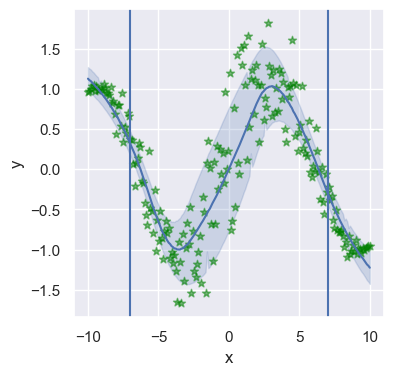

Number of data points within the 95% confidence interval: 132
Percentage of data points within the 95% confidence interval: 66.0
y_vals  [array([[ 1.2479565 ],
       [ 1.2366321 ],
       [ 1.2086842 ],
       [ 1.1923366 ],
       [ 1.1677724 ],
       [ 1.1490058 ],
       [ 1.121631  ],
       [ 1.1017033 ],
       [ 1.0767787 ],
       [ 1.0520774 ],
       [ 1.0231453 ],
       [ 0.99805015],
       [ 0.9703686 ],
       [ 0.9471079 ],
       [ 0.9195687 ],
       [ 0.88753694],
       [ 0.86238676],
       [ 0.8312832 ],
       [ 0.80100816],
       [ 0.77093387],
       [ 0.74014086],
       [ 0.7075939 ],
       [ 0.67520654],
       [ 0.64093244],
       [ 0.6050726 ],
       [ 0.57142746],
       [ 0.5348565 ],
       [ 0.49975747],
       [ 0.4597465 ],
       [ 0.4220303 ],
       [ 0.38095814],
       [ 0.33992547],
       [ 0.29985684],
       [ 0.25402546],
       [ 0.2111676 ],
       [ 0.16780272],
       [ 0.11952038],
       [ 0.07032463],
       [ 0.02182314],
    

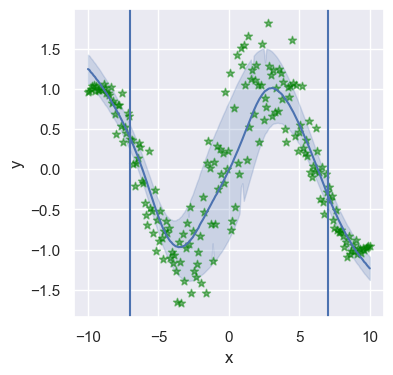

C:\Users\carol\AppData\Local\Temp\ipykernel_53596\2515062465.py:31: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  ax.boxplot(box_plot_data, labels=box_labels)


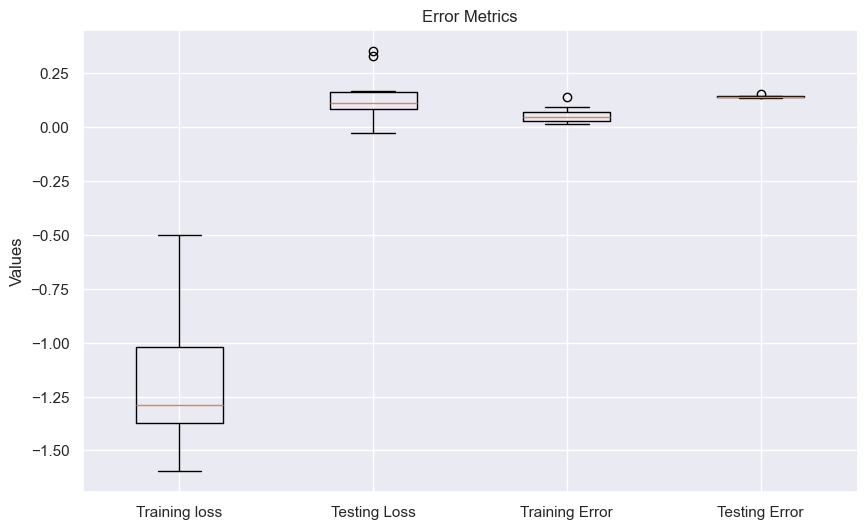

    Training Loss  Testing Loss  Mean Squared Training Error  \
1       -1.594736      0.078667                     0.030645   
2       -0.964367      0.110565                     0.065638   
3       -1.270650      0.329118                     0.033249   
4       -1.517668      0.166057                     0.015193   
5       -1.303928      0.118546                     0.060512   
6       -0.500707      0.154157                     0.095854   
7       -1.312164      0.354879                     0.025244   
8       -1.391173      0.094414                     0.069623   
9       -0.856780     -0.025749                     0.141386   
10      -1.195653      0.023848                     0.039175   

    Mean Squared Testing Error  % of points in Confidence Interval  
1                     0.143458                                65.0  
2                     0.137987                                62.5  
3                     0.141723                                61.5  
4                  

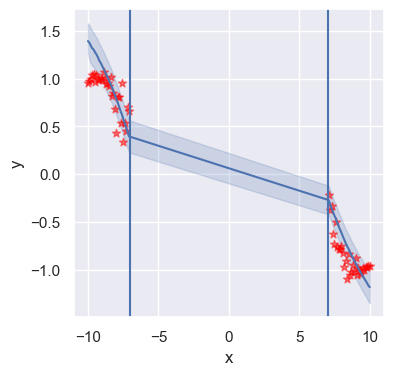

Number of data points within the 95% confidence interval: 35
Percentage of data points within the 95% confidence interval: 58.333333333333336
y_vals  [array([[ 1.414215  ],
       [ 1.3910761 ],
       [ 1.3669214 ],
       [ 1.340536  ],
       [ 1.3147936 ],
       [ 1.2890902 ],
       [ 1.2651199 ],
       [ 1.2342314 ],
       [ 1.2076317 ],
       [ 1.1760838 ],
       [ 1.1465011 ],
       [ 1.1224949 ],
       [ 1.0846504 ],
       [ 1.0568073 ],
       [ 1.0209231 ],
       [ 0.98960227],
       [ 0.9546907 ],
       [ 0.9191736 ],
       [ 0.88100797],
       [ 0.85064775],
       [ 0.81107736],
       [ 0.7721675 ],
       [ 0.73414046],
       [ 0.6948888 ],
       [ 0.6580105 ],
       [ 0.6126052 ],
       [ 0.5705308 ],
       [ 0.52847177],
       [ 0.483899  ],
       [ 0.438939  ],
       [-0.35110995],
       [-0.39474675],
       [-0.43522227],
       [-0.4780073 ],
       [-0.52137494],
       [-0.5634028 ],
       [-0.60279393],
       [-0.64269996],
       [-0.68

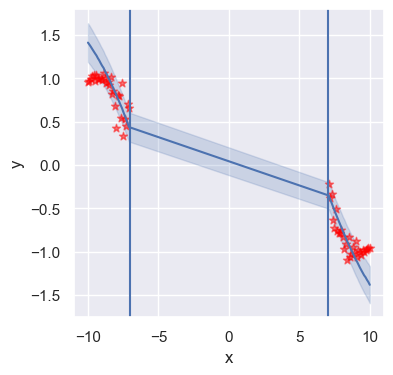

Number of data points within the 95% confidence interval: 39
Percentage of data points within the 95% confidence interval: 65.0
y_vals  [array([[ 1.2904248 ],
       [ 1.269184  ],
       [ 1.2503809 ],
       [ 1.2286673 ],
       [ 1.2074068 ],
       [ 1.1799036 ],
       [ 1.1548389 ],
       [ 1.1307234 ],
       [ 1.1079851 ],
       [ 1.0764424 ],
       [ 1.0491375 ],
       [ 1.0248685 ],
       [ 0.9977692 ],
       [ 0.9639286 ],
       [ 0.93707186],
       [ 0.90656924],
       [ 0.87264913],
       [ 0.84027076],
       [ 0.80691886],
       [ 0.7720701 ],
       [ 0.7347644 ],
       [ 0.70218205],
       [ 0.6648147 ],
       [ 0.6255539 ],
       [ 0.5893364 ],
       [ 0.5484032 ],
       [ 0.50760245],
       [ 0.46439892],
       [ 0.42280868],
       [ 0.3806738 ],
       [-0.34324452],
       [-0.38880235],
       [-0.43912414],
       [-0.4844555 ],
       [-0.5318813 ],
       [-0.5792998 ],
       [-0.6232877 ],
       [-0.6712839 ],
       [-0.71468675],
     

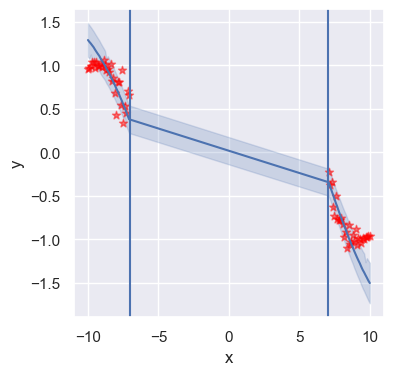

Number of data points within the 95% confidence interval: 31
Percentage of data points within the 95% confidence interval: 51.66666666666667
y_vals  [array([[ 1.3935045 ],
       [ 1.3699515 ],
       [ 1.3412642 ],
       [ 1.3142439 ],
       [ 1.28959   ],
       [ 1.2675546 ],
       [ 1.2392828 ],
       [ 1.2131734 ],
       [ 1.1818544 ],
       [ 1.1553533 ],
       [ 1.1210847 ],
       [ 1.092532  ],
       [ 1.0526959 ],
       [ 1.0280021 ],
       [ 0.9903782 ],
       [ 0.9612719 ],
       [ 0.92339706],
       [ 0.8905451 ],
       [ 0.8495951 ],
       [ 0.8164122 ],
       [ 0.7748491 ],
       [ 0.74129546],
       [ 0.69419724],
       [ 0.65911126],
       [ 0.6129871 ],
       [ 0.57387185],
       [ 0.52741003],
       [ 0.48827994],
       [ 0.43771338],
       [ 0.3902223 ],
       [-0.37621406],
       [-0.4210874 ],
       [-0.4666128 ],
       [-0.5116541 ],
       [-0.55937487],
       [-0.6018026 ],
       [-0.64254564],
       [-0.6876864 ],
       [-0.731

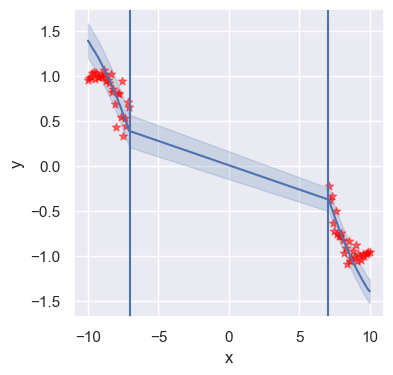

Number of data points within the 95% confidence interval: 35
Percentage of data points within the 95% confidence interval: 58.333333333333336
y_vals  [array([[ 1.0427723 ],
       [ 1.0345576 ],
       [ 1.0153041 ],
       [ 1.004093  ],
       [ 0.98642886],
       [ 0.9712939 ],
       [ 0.9539734 ],
       [ 0.93885386],
       [ 0.918873  ],
       [ 0.9017917 ],
       [ 0.87719625],
       [ 0.86215705],
       [ 0.8407533 ],
       [ 0.8176766 ],
       [ 0.79369473],
       [ 0.7735187 ],
       [ 0.7459302 ],
       [ 0.721121  ],
       [ 0.6934095 ],
       [ 0.66628325],
       [ 0.63630456],
       [ 0.6070588 ],
       [ 0.5742188 ],
       [ 0.54497635],
       [ 0.5074077 ],
       [ 0.4737042 ],
       [ 0.43372405],
       [ 0.39709088],
       [ 0.3575993 ],
       [ 0.31836927],
       [-0.3210891 ],
       [-0.36489514],
       [-0.41083455],
       [-0.45223826],
       [-0.49857095],
       [-0.54290134],
       [-0.58451235],
       [-0.6271062 ],
       [-0.66

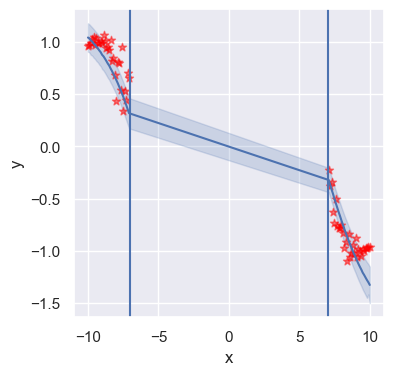

Number of data points within the 95% confidence interval: 34
Percentage of data points within the 95% confidence interval: 56.666666666666664
y_vals  [array([[ 1.4568175 ],
       [ 1.4322549 ],
       [ 1.4092038 ],
       [ 1.3794844 ],
       [ 1.353571  ],
       [ 1.3203195 ],
       [ 1.299947  ],
       [ 1.2653521 ],
       [ 1.2383685 ],
       [ 1.2051399 ],
       [ 1.177805  ],
       [ 1.1409867 ],
       [ 1.107838  ],
       [ 1.0784358 ],
       [ 1.044036  ],
       [ 1.0115613 ],
       [ 0.9735131 ],
       [ 0.93724394],
       [ 0.899915  ],
       [ 0.86143243],
       [ 0.8242094 ],
       [ 0.7822206 ],
       [ 0.74277204],
       [ 0.7007444 ],
       [ 0.65944445],
       [ 0.6178464 ],
       [ 0.57341874],
       [ 0.5310536 ],
       [ 0.48613808],
       [ 0.4377779 ],
       [-0.3691342 ],
       [-0.41229403],
       [-0.45529827],
       [-0.49987695],
       [-0.5408099 ],
       [-0.584526  ],
       [-0.62404585],
       [-0.6641159 ],
       [-0.70

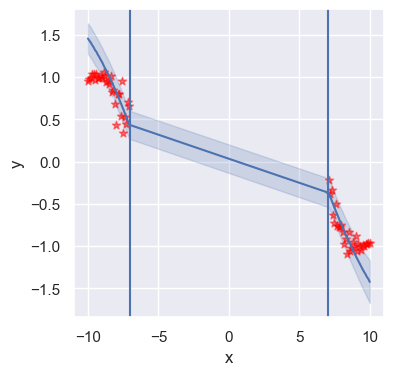

Number of data points within the 95% confidence interval: 45
Percentage of data points within the 95% confidence interval: 75.0
y_vals  [array([[ 1.2677357 ],
       [ 1.2487279 ],
       [ 1.2299663 ],
       [ 1.2093801 ],
       [ 1.1896503 ],
       [ 1.1637691 ],
       [ 1.1426549 ],
       [ 1.1240108 ],
       [ 1.096453  ],
       [ 1.0746914 ],
       [ 1.048781  ],
       [ 1.0193148 ],
       [ 0.9940181 ],
       [ 0.9696234 ],
       [ 0.93771863],
       [ 0.9133165 ],
       [ 0.8818432 ],
       [ 0.8502901 ],
       [ 0.8205845 ],
       [ 0.7886009 ],
       [ 0.75397   ],
       [ 0.72288305],
       [ 0.68766886],
       [ 0.65080637],
       [ 0.613765  ],
       [ 0.57846135],
       [ 0.53799677],
       [ 0.49945378],
       [ 0.45764512],
       [ 0.41675484],
       [-0.39992225],
       [-0.44294506],
       [-0.4817324 ],
       [-0.51758176],
       [-0.55934983],
       [-0.5928591 ],
       [-0.6342729 ],
       [-0.6643255 ],
       [-0.6985845 ],
     

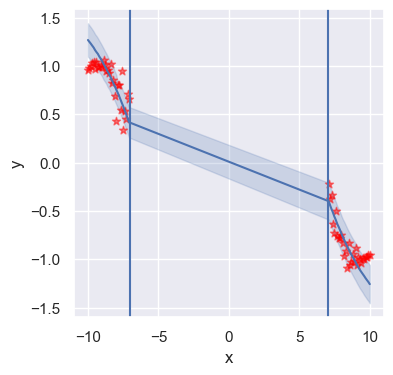

Number of data points within the 95% confidence interval: 41
Percentage of data points within the 95% confidence interval: 68.33333333333333
y_vals  [array([[ 1.113219  ],
       [ 1.0999031 ],
       [ 1.0861357 ],
       [ 1.0682083 ],
       [ 1.0527925 ],
       [ 1.0350335 ],
       [ 1.0167774 ],
       [ 0.9996196 ],
       [ 0.98362213],
       [ 0.96248174],
       [ 0.9456504 ],
       [ 0.9247063 ],
       [ 0.90128934],
       [ 0.885157  ],
       [ 0.8595559 ],
       [ 0.837299  ],
       [ 0.8136894 ],
       [ 0.7897744 ],
       [ 0.76496375],
       [ 0.73961914],
       [ 0.7125501 ],
       [ 0.6842673 ],
       [ 0.6546296 ],
       [ 0.62636817],
       [ 0.5945165 ],
       [ 0.56347984],
       [ 0.52976954],
       [ 0.49592593],
       [ 0.46047854],
       [ 0.42330033],
       [-0.41786483],
       [-0.46151963],
       [-0.502985  ],
       [-0.5431504 ],
       [-0.5857284 ],
       [-0.6244734 ],
       [-0.6635664 ],
       [-0.702637  ],
       [-0.737

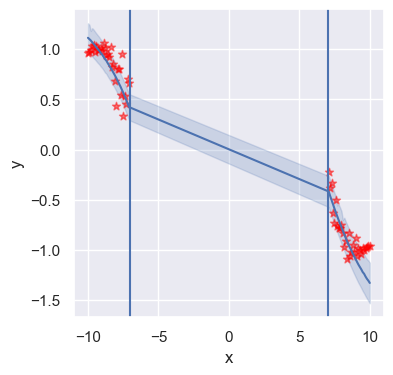

Number of data points within the 95% confidence interval: 40
Percentage of data points within the 95% confidence interval: 66.66666666666666
y_vals  [array([[ 1.3418354 ],
       [ 1.314839  ],
       [ 1.2909819 ],
       [ 1.270476  ],
       [ 1.2372583 ],
       [ 1.2131308 ],
       [ 1.1897615 ],
       [ 1.1557512 ],
       [ 1.1319386 ],
       [ 1.098428  ],
       [ 1.0745838 ],
       [ 1.0411928 ],
       [ 1.0098424 ],
       [ 0.9771916 ],
       [ 0.94380575],
       [ 0.9066652 ],
       [ 0.87499505],
       [ 0.83990777],
       [ 0.80468124],
       [ 0.77167165],
       [ 0.73010314],
       [ 0.6906923 ],
       [ 0.6519069 ],
       [ 0.6142031 ],
       [ 0.57475734],
       [ 0.53144664],
       [ 0.49045068],
       [ 0.44589645],
       [ 0.40372124],
       [ 0.35748377],
       [-0.32394138],
       [-0.36071438],
       [-0.3994525 ],
       [-0.4385564 ],
       [-0.47337496],
       [-0.5100898 ],
       [-0.54530054],
       [-0.58258176],
       [-0.615

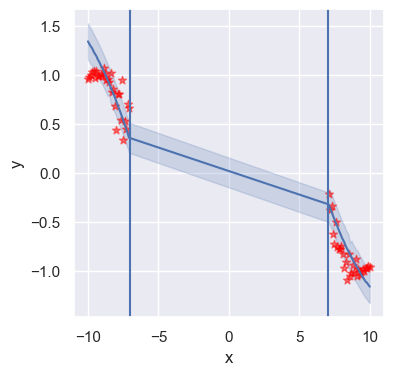

Number of data points within the 95% confidence interval: 34
Percentage of data points within the 95% confidence interval: 56.666666666666664
y_vals  [array([[ 1.2288883 ],
       [ 1.2097319 ],
       [ 1.1917945 ],
       [ 1.1723212 ],
       [ 1.1494905 ],
       [ 1.1361028 ],
       [ 1.1100142 ],
       [ 1.0897962 ],
       [ 1.067329  ],
       [ 1.0445791 ],
       [ 1.0237856 ],
       [ 0.9958445 ],
       [ 0.9716639 ],
       [ 0.9433319 ],
       [ 0.9181728 ],
       [ 0.8906383 ],
       [ 0.8608322 ],
       [ 0.83283406],
       [ 0.8001665 ],
       [ 0.77131546],
       [ 0.7356068 ],
       [ 0.70329756],
       [ 0.6665789 ],
       [ 0.6314769 ],
       [ 0.5924969 ],
       [ 0.5543578 ],
       [ 0.51521474],
       [ 0.47390667],
       [ 0.4330645 ],
       [ 0.38765803],
       [-0.34557182],
       [-0.39075646],
       [-0.4333311 ],
       [-0.47922227],
       [-0.5218583 ],
       [-0.5644203 ],
       [-0.60631526],
       [-0.64823586],
       [-0.69

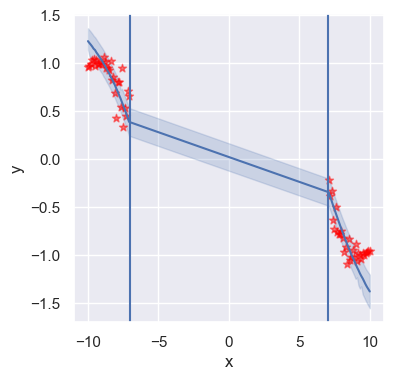

C:\Users\carol\AppData\Local\Temp\ipykernel_53596\2515062465.py:31: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  ax.boxplot(box_plot_data, labels=box_labels)


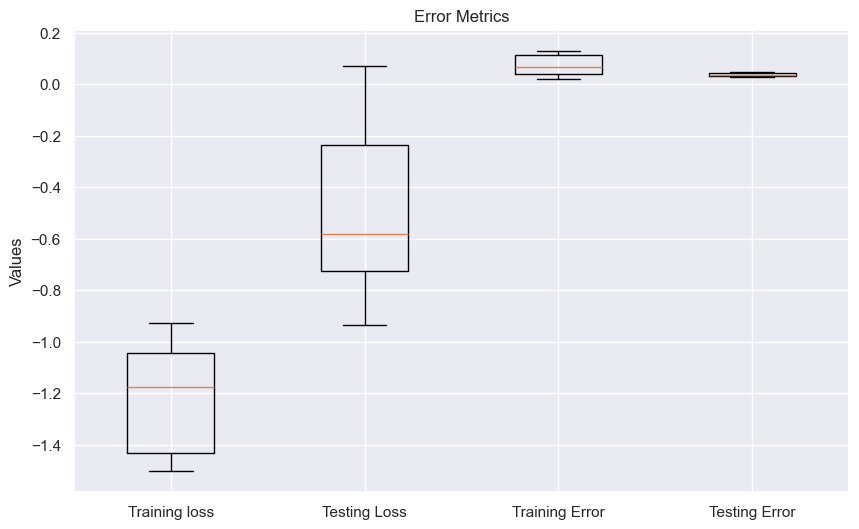

    Training Loss  Testing Loss  Mean Squared Training Error  \
1       -1.098369      0.070792                     0.128968   
2       -1.488189     -0.503676                     0.020228   
3       -0.959676     -0.267421                     0.056809   
4       -0.927874     -0.158480                     0.083554   
5       -1.484220     -0.921700                     0.018659   
6       -1.274052     -0.226084                     0.072871   
7       -1.031683     -0.935638                     0.129512   
8       -1.250448     -0.664738                     0.038468   
9       -1.501610     -0.744294                     0.042299   
10      -1.077398     -0.656397                     0.122126   

    Mean Squared Testing Error  % of points in Confidence Interval  
1                     0.047468                           53.333333  
2                     0.039166                           58.333333  
3                     0.046857                           65.000000  
4                  

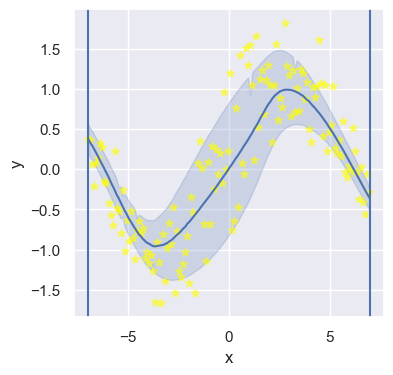

Number of data points within the 95% confidence interval: 92
Percentage of data points within the 95% confidence interval: 65.71428571428571
y_vals  [array([[ 0.36372766],
       [ 0.32042372],
       [ 0.27359053],
       [ 0.22815914],
       [ 0.18033548],
       [ 0.13160986],
       [ 0.08378199],
       [ 0.03168591],
       [-0.01794342],
       [-0.07014017],
       [-0.12021723],
       [-0.17219484],
       [-0.22564907],
       [-0.27493083],
       [-0.32947204],
       [-0.38208476],
       [-0.4311691 ],
       [-0.47607943],
       [-0.53069514],
       [-0.5788162 ],
       [-0.62211084],
       [-0.6705791 ],
       [-0.7112838 ],
       [-0.7532502 ],
       [-0.7970925 ],
       [-0.83209616],
       [-0.8612038 ],
       [-0.89699835],
       [-0.92179686],
       [-0.9457449 ],
       [-0.9657522 ],
       [-0.9812554 ],
       [-0.9956648 ],
       [-0.9956586 ],
       [-0.99979126],
       [-1.0014116 ],
       [-0.9937578 ],
       [-0.9836151 ],
       [-0.971

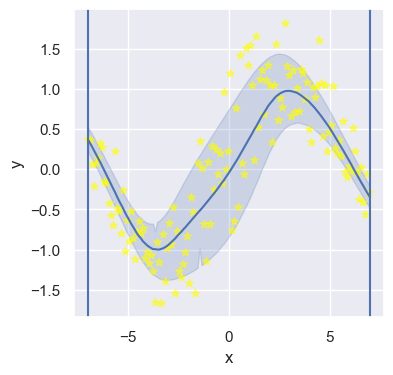

Number of data points within the 95% confidence interval: 96
Percentage of data points within the 95% confidence interval: 68.57142857142857
y_vals  [array([[ 0.2472157 ],
       [ 0.20230766],
       [ 0.15397187],
       [ 0.11125354],
       [ 0.06392211],
       [ 0.01347043],
       [-0.03653349],
       [-0.08602187],
       [-0.13577208],
       [-0.18679617],
       [-0.23445635],
       [-0.28950712],
       [-0.33745876],
       [-0.38779342],
       [-0.43867996],
       [-0.49191704],
       [-0.5430629 ],
       [-0.59258455],
       [-0.6386763 ],
       [-0.6857109 ],
       [-0.73139554],
       [-0.7760042 ],
       [-0.8164469 ],
       [-0.85811263],
       [-0.89543486],
       [-0.92889196],
       [-0.9625631 ],
       [-0.99492395],
       [-1.0169867 ],
       [-1.0399354 ],
       [-1.0524524 ],
       [-1.0703095 ],
       [-1.0773114 ],
       [-1.0800191 ],
       [-1.0798594 ],
       [-1.0760577 ],
       [-1.0662018 ],
       [-1.0521337 ],
       [-1.037

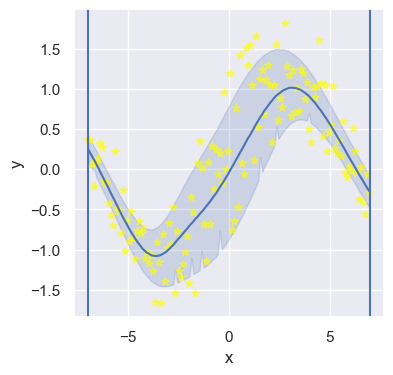

Number of data points within the 95% confidence interval: 93
Percentage of data points within the 95% confidence interval: 66.42857142857143
y_vals  [array([[ 0.33827606],
       [ 0.291179  ],
       [ 0.24743624],
       [ 0.20297427],
       [ 0.15025097],
       [ 0.10108937],
       [ 0.05237144],
       [ 0.00303221],
       [-0.05032184],
       [-0.10165865],
       [-0.1531971 ],
       [-0.20656686],
       [-0.25828886],
       [-0.30801564],
       [-0.36143142],
       [-0.4129398 ],
       [-0.46229836],
       [-0.5133252 ],
       [-0.561486  ],
       [-0.60740954],
       [-0.6495994 ],
       [-0.6961477 ],
       [-0.73233724],
       [-0.77261525],
       [-0.8067845 ],
       [-0.839979  ],
       [-0.87237036],
       [-0.9006977 ],
       [-0.9236681 ],
       [-0.9428633 ],
       [-0.96315455],
       [-0.9802176 ],
       [-0.9904615 ],
       [-1.0004051 ],
       [-1.003634  ],
       [-1.0078491 ],
       [-1.0069966 ],
       [-1.0017985 ],
       [-0.992

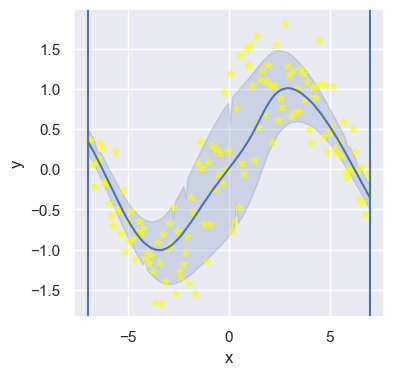

Number of data points within the 95% confidence interval: 92
Percentage of data points within the 95% confidence interval: 65.71428571428571
y_vals  [array([[ 3.52101624e-01],
       [ 3.02538574e-01],
       [ 2.54340142e-01],
       [ 2.03895211e-01],
       [ 1.55153617e-01],
       [ 1.02209613e-01],
       [ 5.53074740e-02],
       [ 3.03183857e-04],
       [-5.24443239e-02],
       [-1.01779193e-01],
       [-1.54034868e-01],
       [-2.07091719e-01],
       [-2.57736385e-01],
       [-3.08805913e-01],
       [-3.58485311e-01],
       [-4.08127248e-01],
       [-4.59144324e-01],
       [-5.05776584e-01],
       [-5.53065240e-01],
       [-5.99205613e-01],
       [-6.42521441e-01],
       [-6.89272106e-01],
       [-7.31110632e-01],
       [-7.68423855e-01],
       [-8.08139443e-01],
       [-8.41454923e-01],
       [-8.79251957e-01],
       [-9.08735573e-01],
       [-9.34144437e-01],
       [-9.56555545e-01],
       [-9.80288267e-01],
       [-9.95069563e-01],
       [-1.0048719

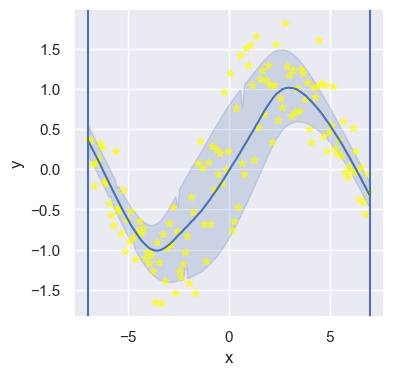

Number of data points within the 95% confidence interval: 95
Percentage of data points within the 95% confidence interval: 67.85714285714286
y_vals  [array([[ 0.34570798],
       [ 0.2983063 ],
       [ 0.25092196],
       [ 0.1989156 ],
       [ 0.14976779],
       [ 0.10257363],
       [ 0.05025302],
       [ 0.00247607],
       [-0.0501109 ],
       [-0.10253641],
       [-0.15240923],
       [-0.20310196],
       [-0.2548538 ],
       [-0.30414858],
       [-0.3558809 ],
       [-0.40701115],
       [-0.4564947 ],
       [-0.5050199 ],
       [-0.55419344],
       [-0.5985651 ],
       [-0.64271426],
       [-0.68512845],
       [-0.72805476],
       [-0.76763606],
       [-0.8050183 ],
       [-0.8346931 ],
       [-0.8685001 ],
       [-0.9005934 ],
       [-0.92456573],
       [-0.94920725],
       [-0.96468985],
       [-0.98288506],
       [-0.9951698 ],
       [-1.0000848 ],
       [-1.0078663 ],
       [-1.0045258 ],
       [-0.99594843],
       [-0.98939127],
       [-0.976

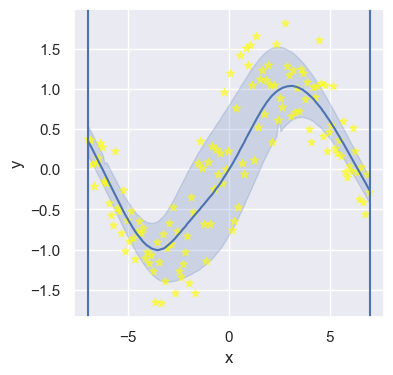

Number of data points within the 95% confidence interval: 91
Percentage of data points within the 95% confidence interval: 65.0
y_vals  [array([[ 0.38995564],
       [ 0.34766084],
       [ 0.3026182 ],
       [ 0.25746724],
       [ 0.20648688],
       [ 0.15800597],
       [ 0.10995201],
       [ 0.0606503 ],
       [ 0.01323536],
       [-0.03979218],
       [-0.09006668],
       [-0.14564525],
       [-0.19504999],
       [-0.24812779],
       [-0.2989764 ],
       [-0.3498197 ],
       [-0.40066314],
       [-0.45275134],
       [-0.50149024],
       [-0.5499367 ],
       [-0.59918875],
       [-0.64462066],
       [-0.6931915 ],
       [-0.7391869 ],
       [-0.7819306 ],
       [-0.8151253 ],
       [-0.85114914],
       [-0.8858695 ],
       [-0.90816885],
       [-0.9343297 ],
       [-0.95216584],
       [-0.9689091 ],
       [-0.98494905],
       [-0.9886271 ],
       [-0.990779  ],
       [-0.988085  ],
       [-0.9797969 ],
       [-0.9645603 ],
       [-0.9533924 ],
     

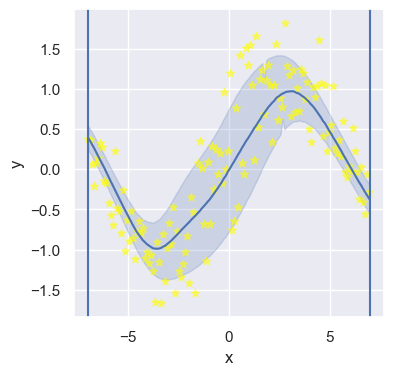

Number of data points within the 95% confidence interval: 93
Percentage of data points within the 95% confidence interval: 66.42857142857143
y_vals  [array([[ 0.37640834],
       [ 0.3321637 ],
       [ 0.28458196],
       [ 0.23713951],
       [ 0.1887557 ],
       [ 0.14133424],
       [ 0.09014381],
       [ 0.04031135],
       [-0.00873217],
       [-0.06389503],
       [-0.11241955],
       [-0.16603094],
       [-0.22062007],
       [-0.27132306],
       [-0.32290477],
       [-0.3749892 ],
       [-0.4221561 ],
       [-0.47333658],
       [-0.52679724],
       [-0.5749428 ],
       [-0.61928725],
       [-0.66121155],
       [-0.7067209 ],
       [-0.74258447],
       [-0.7836609 ],
       [-0.8162367 ],
       [-0.8464281 ],
       [-0.8784404 ],
       [-0.9031276 ],
       [-0.9278856 ],
       [-0.942279  ],
       [-0.9639501 ],
       [-0.9784695 ],
       [-0.9832026 ],
       [-0.9929346 ],
       [-0.99319196],
       [-0.99262637],
       [-0.99059415],
       [-0.985

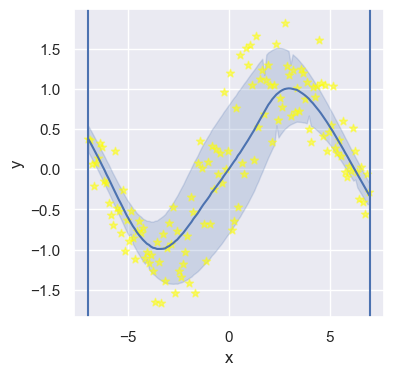

Number of data points within the 95% confidence interval: 90
Percentage of data points within the 95% confidence interval: 64.28571428571429
y_vals  [array([[ 0.33476213],
       [ 0.29623738],
       [ 0.25465074],
       [ 0.21450903],
       [ 0.17157584],
       [ 0.12794073],
       [ 0.08325928],
       [ 0.03703153],
       [-0.0120458 ],
       [-0.06190522],
       [-0.11273319],
       [-0.16645928],
       [-0.21914904],
       [-0.2715637 ],
       [-0.32551712],
       [-0.3823576 ],
       [-0.43600473],
       [-0.48856297],
       [-0.5440104 ],
       [-0.5916509 ],
       [-0.64293885],
       [-0.6863028 ],
       [-0.730183  ],
       [-0.7728495 ],
       [-0.80944896],
       [-0.84680307],
       [-0.8816698 ],
       [-0.9011933 ],
       [-0.92596024],
       [-0.9476428 ],
       [-0.9637191 ],
       [-0.9806284 ],
       [-0.9851807 ],
       [-0.993154  ],
       [-0.992363  ],
       [-0.9892167 ],
       [-0.98745894],
       [-0.9758688 ],
       [-0.961

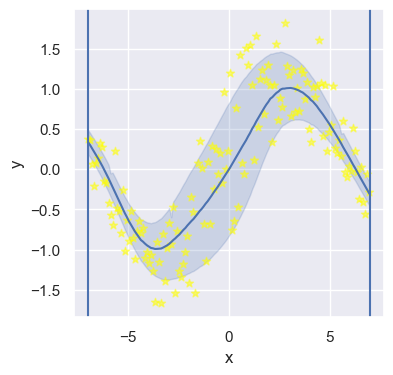

Number of data points within the 95% confidence interval: 89
Percentage of data points within the 95% confidence interval: 63.57142857142857
y_vals  [array([[ 0.33401412],
       [ 0.29306176],
       [ 0.2526255 ],
       [ 0.20817581],
       [ 0.16314022],
       [ 0.11740725],
       [ 0.06929789],
       [ 0.02082876],
       [-0.02779971],
       [-0.07900218],
       [-0.13066381],
       [-0.1836682 ],
       [-0.23682559],
       [-0.2918471 ],
       [-0.3444753 ],
       [-0.3977498 ],
       [-0.45092982],
       [-0.50419295],
       [-0.5535177 ],
       [-0.60226583],
       [-0.6516598 ],
       [-0.6931667 ],
       [-0.73708963],
       [-0.7778757 ],
       [-0.81907827],
       [-0.8518255 ],
       [-0.8809695 ],
       [-0.9116002 ],
       [-0.93881124],
       [-0.9595892 ],
       [-0.97671854],
       [-0.9911615 ],
       [-1.0041901 ],
       [-1.0105962 ],
       [-1.0107408 ],
       [-1.0119127 ],
       [-1.0053353 ],
       [-0.9950344 ],
       [-0.983

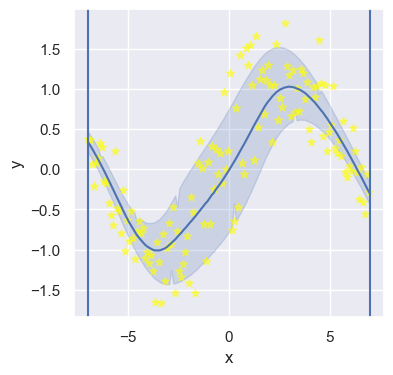

C:\Users\carol\AppData\Local\Temp\ipykernel_53596\2515062465.py:31: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  ax.boxplot(box_plot_data, labels=box_labels)


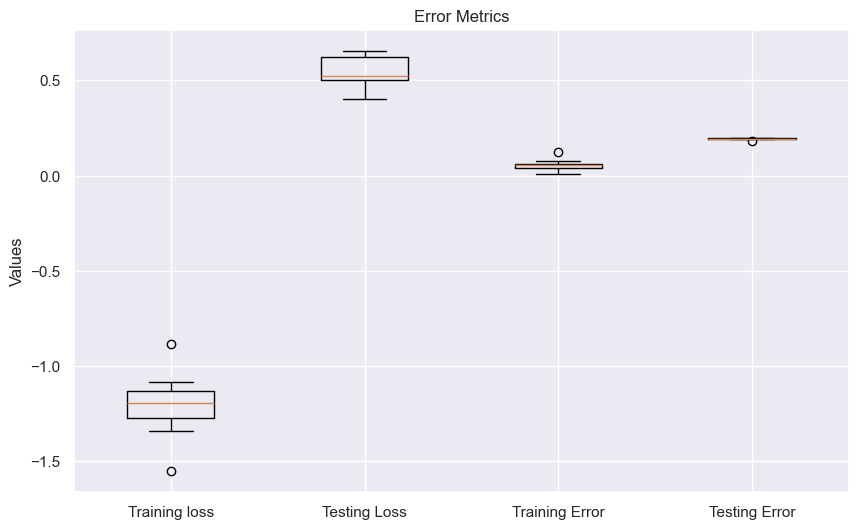

    Training Loss  Testing Loss  Mean Squared Training Error  \
1       -1.088141      0.505350                     0.051120   
2       -1.224885      0.537664                     0.078581   
3       -1.340951      0.500880                     0.040529   
4       -1.119062      0.655809                     0.034173   
5       -1.167512      0.636537                     0.037533   
6       -1.171416      0.624228                     0.058054   
7       -0.885418      0.402372                     0.126324   
8       -1.273179      0.465929                     0.063838   
9       -1.552614      0.504308                     0.009284   
10      -1.270505      0.618374                     0.056563   

    Mean Squared Testing Error  % of points in Confidence Interval  
1                     0.197601                           66.428571  
2                     0.191763                           65.714286  
3                     0.194072                           68.571429  
4                  

In [17]:
for tst_loader,tnsor_x_test,tnsor_y_test, col, x_test,y_test,output_dir, error_metric in zip(test_loaders,test_tensors_x,test_tensors_y,color,testset_x,testset_y,output_dirs,error_mets):
  train_losses=[]
  test_losses=[]
  errors_train=[]
  errors_test=[]
  percentages_count_within_ci=[]
  for i in range(10):
    net=DeepONet()
    tr_loss,test_loss,mse_tr,mse_test,model,percentage_count_within_ci = Neural_Network(net,train_loader,test_loader_vars[tst_loader],
    tensor_x_mapping[tnsor_x_test],tensor_y_mapping[tnsor_y_test],
                   testset_x_mapping[x_test],testset_y_mapping[y_test],col)
    error_metrics=tr_loss,test_loss,mse_tr,mse_test,model,percentage_count_within_ci
    model_filename = f"{output_dir}model_{i}.pkl"
    with open(model_filename, 'wb') as file:
      pickle.dump(error_metrics, file)
    train_losses.append(tr_loss)
    test_losses.append(test_loss)
    errors_train.append(mse_tr)
    errors_test.append(mse_test)
    percentages_count_within_ci.append(percentage_count_within_ci)
  # Extract numerical values from the tensors and remove grad_fn
  tr_loss_values= [tensor.item() for tensor in train_losses]
  test_loss_values=test_losses
  tr_errors_values= [tensor.item() for tensor in errors_train]
  test_errors_values= errors_test
  # Create a figure and axis
  fig, ax = plt.subplots(figsize=(10, 6))
  # Create box plots for each dataset
  box_plot_data = [tr_loss_values, test_loss_values, tr_errors_values, test_errors_values]
  box_labels = ['Training loss', 'Testing Loss', 'Training Error', 'Testing Error']
  ax.boxplot(box_plot_data, labels=box_labels)
  # Add labels and title
  ax.set_ylabel('Values')
  ax.set_title('Error Metrics')
  plt.savefig(f'donn_arch_{error_metric}.png', dpi=300)
  # Show the plot
  plt.show()

  mean_gaus_train_loss = np.mean(tr_loss_values)
  std_dev_gaus_train_loss = np.std(tr_loss_values)

  mean_gaus_test_loss = np.mean(test_loss_values)
  std_dev_gaus_test_loss = np.std(test_loss_values)

  mean_mse_train = np.mean(tr_errors_values)
  std_dev_mse_train = np.std(tr_errors_values)

  mean_mse_test = np.mean(test_errors_values)
  std_dev_mse_test = np.std(test_errors_values)

  mean_percentages_count_within_ci = np.mean(percentages_count_within_ci)
  std_dev_percentages_count_within_ci = np.std(percentages_count_within_ci)

  # Create a DataFrame from the lists
  data = {
    'Training Loss': tr_loss_values,
    'Testing Loss': test_loss_values,
    'Mean Squared Training Error': tr_errors_values,
    'Mean Squared Testing Error': test_errors_values,
    '% of points in Confidence Interval':percentages_count_within_ci,
  }

  num_columns = len(data)

  column_names = ['Training Loss','Testing Loss', 'Mean Squared Training Error','Mean Squared Testing Error','% of points in Confidence Interval']
  # Create a DataFrame with dynamic column names
  df = pd.DataFrame(data, columns=column_names)
  df.index += 1
  # Display the DataFrame as a table
  print(df)
  df.to_csv(f'donn_results_{error_metric}.txt', index=True)
  print('Mean of Gausiann Training Loss of 10 runs ', mean_gaus_train_loss)
  print('Standard Deviation of Gausiann Training Loss of 10 runs ' , std_dev_gaus_train_loss )

  print('Mean of Gausiann Testing Loss of 10 runs ',mean_gaus_test_loss )
  print('Standard Deviation of Gausiann Testing Loss of 10 runs ',std_dev_gaus_test_loss)

  print('Mean of MSE Training of 10 runs ',mean_mse_train)
  print('Standard Deviation of MSE Training of 10 runs ' , std_dev_mse_train)

  print('Mean of MSE Testing of 10 runs ',mean_mse_test )
  print('Standard Deviation of MSE Testing of 10 runs ', std_dev_mse_test)

  print('Mean of percentage of 95% conf interval for 10 runs in data',mean_percentages_count_within_ci)
  print('Standard Deviation of percentage of 95% conf interval for 10 runs in data ' , std_dev_percentages_count_within_ci)

  # File path
  file_path = f'donn_summary_{error_metric}.txt'

  # Open the file in write mode
  with open(file_path, 'w') as file:
    # Write the results to the file
    file.write('Mean of Gaussian Training Loss of 10 runs: {}\n'.format(mean_gaus_train_loss))
    file.write('Standard Deviation of Gaussian Training Loss of 10 runs: {}\n\n'.format(std_dev_gaus_train_loss))

    file.write('Mean of Gaussian Testing Loss of 10 runs: {}\n'.format(mean_gaus_test_loss))
    file.write('Standard Deviation of Gaussian Testing Loss of 10 runs: {}\n\n'.format(std_dev_gaus_test_loss))

    file.write('Mean of MSE Training of 10 runs: {}\n'.format(mean_mse_train))
    file.write('Standard Deviation of MSE Training of 10 runs: {}\n\n'.format(std_dev_mse_train))

    file.write('Mean of MSE Testing of 10 runs: {}\n'.format(mean_mse_test))
    file.write('Standard Deviation of MSE Testing of 10 runs: {}\n\n'.format(std_dev_mse_test))

    file.write('Mean of percentage of 95% conf interval for 10 runs in data {}\n'.format(mean_percentages_count_within_ci))
    file.write('Standard Deviation of percentage of 95% conf interval for 10 runs in data {}\n\n'.format(std_dev_percentages_count_within_ci))

  # Print a message indicating the file has been saved
  print(f'Results summary saved to {file_path}')
